In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay, accuracy_score
from src.pre_process_filter import build_table, person_table, FEATURE_NAMES
pd.set_option("display.max_columns", None)
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [2]:
OWN = "../data/own_raw"

p1 = person_table("P1", f"{OWN}/P1")
p2 = person_table("P2", f"{OWN}/P2")
p3 = person_table("P3", f"{OWN}/P3")
group = pd.concat([p1, p2, p3], ignore_index=True)
print(group.shape)
pd.crosstab(group["activity"], group["user"])

(1307, 29)


user,P1,P2,P3
activity,,,
sit_to_stand,22,10,20
sitting,142,124,132
stand_to_sit,22,10,21
standing,142,128,132
walking,135,137,130


In [3]:
hapt = build_table("../data/hapt_raw/RawData")
print(hapt.shape)

(5605, 29)


In [4]:
BASE = FEATURE_NAMES[:24]   # the original 24 features (without the 3 change features)
results = {}                # every experiment's macro F1, for the summary at the end


def report(true, predictions, name):
    """Print the scores, save the macro F1, and draw the confusion matrix."""
    print(name)
    print("Accuracy:", accuracy_score(true, predictions))
    print(classification_report(true, predictions))
    results[name] = f1_score(true, predictions, average="macro")
    ConfusionMatrixDisplay.from_predictions(true, predictions, xticks_rotation=45)
    plt.title(name)
    plt.tight_layout()
    plt.show()

In [5]:
def leave_one_person_out(cols, name, extra_train=None, svm=False):
    """Train on two group members, test on the third. Repeat for each person."""
    all_true = []
    all_pred = []

    for person in group["user"].unique():
        # This person is the test set; everyone else is the training set
        is_person = group["user"] == person
        test = group[is_person]
        train = group[is_person == False]

        # Optionally add extra training data (e.g. HAPT)
        if extra_train is not None:
            train = pd.concat([extra_train, train])

        # Train a new model, then test it on the person it has never seen
        if svm:
            person_model = make_pipeline(StandardScaler(), SVC())
        else:
            person_model = RandomForestClassifier(n_estimators=100, random_state=42)
        person_model.fit(train[cols], train["activity"])
        predictions = person_model.predict(test[cols])

        # Keep the real answers and predictions from every round
        all_true.extend(test["activity"])
        all_pred.extend(predictions)

    # Score all three rounds together
    report(all_true, all_pred, name)

HAPT model on our group
Accuracy: 0.6296863045141545
              precision    recall  f1-score   support

sit_to_stand       0.88      0.40      0.55        52
     sitting       0.99      0.89      0.94       398
stand_to_sit       0.10      0.92      0.18        53
    standing       0.89      0.99      0.94       402
     walking       0.00      0.00      0.00       402

    accuracy                           0.63      1307
   macro avg       0.57      0.64      0.52      1307
weighted avg       0.61      0.63      0.60      1307



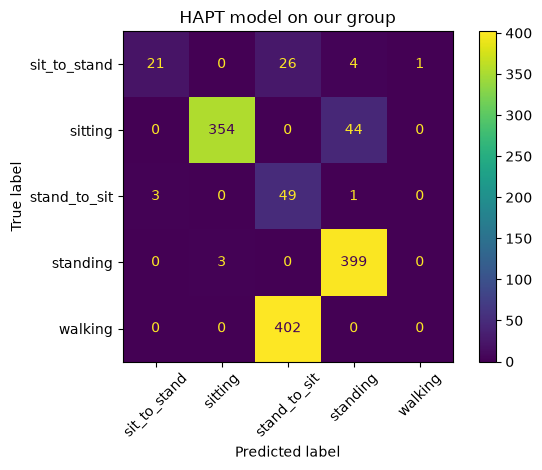

In [6]:
hapt_model = RandomForestClassifier(n_estimators=100, random_state=42)
hapt_model.fit(hapt[BASE], hapt["activity"])
predictions = hapt_model.predict(group[BASE])
report(group["activity"], predictions, "HAPT model on our group")

HAPT + group, new person
Accuracy: 0.8454475899005356
              precision    recall  f1-score   support

sit_to_stand       0.74      0.48      0.58        52
     sitting       1.00      0.94      0.97       398
stand_to_sit       0.19      0.70      0.30        53
    standing       0.94      1.00      0.97       402
     walking       0.96      0.66      0.78       402

    accuracy                           0.85      1307
   macro avg       0.76      0.76      0.72      1307
weighted avg       0.92      0.85      0.87      1307



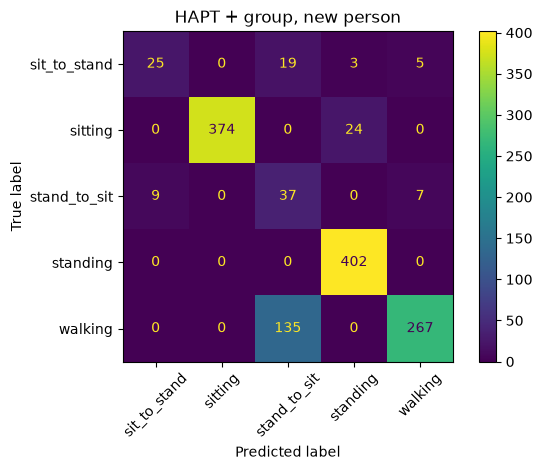

In [7]:
leave_one_person_out(BASE, "HAPT + group, new person", extra_train=hapt)

group only, new person
Accuracy: 0.9716908951798011
              precision    recall  f1-score   support

sit_to_stand       0.96      0.46      0.62        52
     sitting       1.00      1.00      1.00       398
stand_to_sit       0.66      0.83      0.73        53
    standing       1.00      1.00      1.00       402
     walking       0.97      1.00      0.99       402

    accuracy                           0.97      1307
   macro avg       0.92      0.86      0.87      1307
weighted avg       0.97      0.97      0.97      1307



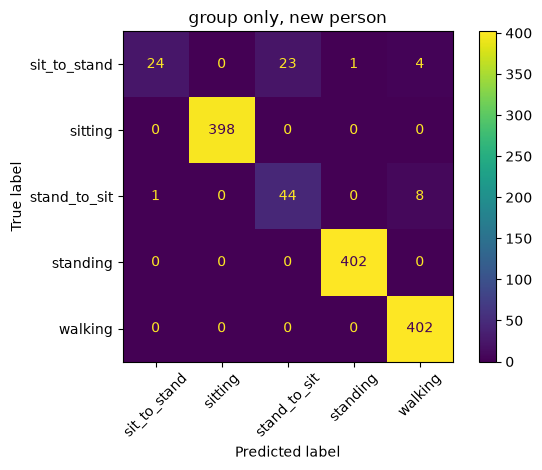

In [8]:
leave_one_person_out(BASE, "group only, new person")

group only + change features
Accuracy: 0.9824024483550114
              precision    recall  f1-score   support

sit_to_stand       1.00      0.69      0.82        52
     sitting       1.00      1.00      1.00       398
stand_to_sit       1.00      0.87      0.93        53
    standing       0.97      1.00      0.99       402
     walking       0.97      1.00      0.99       402

    accuracy                           0.98      1307
   macro avg       0.99      0.91      0.94      1307
weighted avg       0.98      0.98      0.98      1307



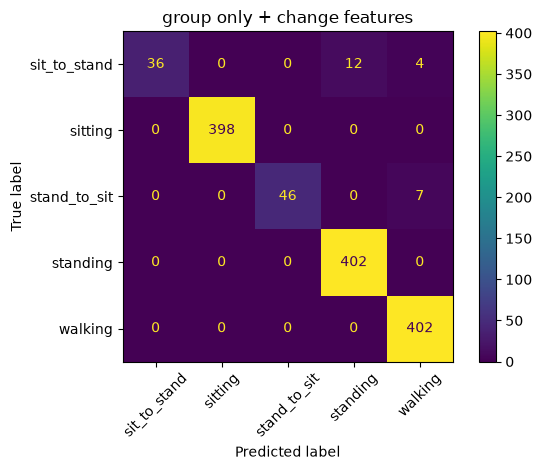

In [9]:
leave_one_person_out(FEATURE_NAMES, "group only + change features")

mean_acc_y    0.165138
min_acc_y     0.131271
std_gyro_x    0.116267
max_acc_y     0.107082
std_acc_z     0.051503
std_gyro_y    0.050653
std_gyro_z    0.043107
max_gyro_x    0.040488
max_acc_z     0.037596
std_acc_y     0.034146
dtype: float64


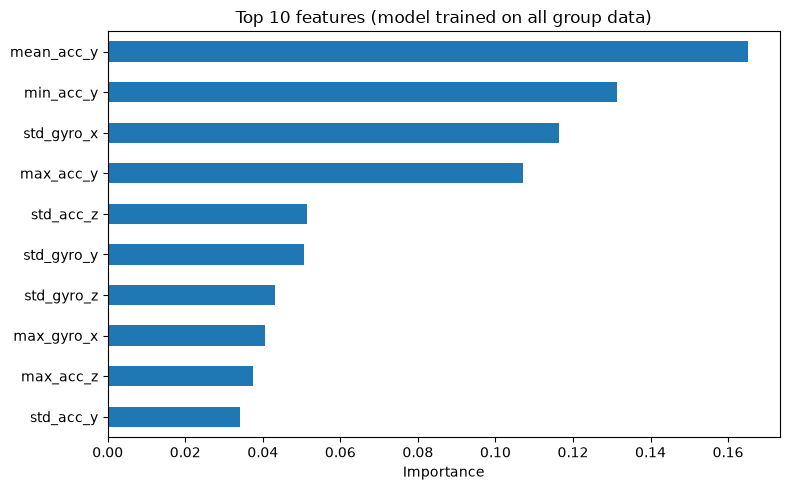

In [10]:
final_model = RandomForestClassifier(n_estimators=100, random_state=42)
final_model.fit(group[FEATURE_NAMES], group["activity"])

importance = pd.Series(final_model.feature_importances_, index=FEATURE_NAMES)
importance = importance.sort_values(ascending=False)
print(importance.head(10))

importance.head(10).plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 10 features (model trained on all group data)")
plt.tight_layout()
plt.show()

(SVM): HAPT model on our group
Accuracy: 0.14843152257077277
              precision    recall  f1-score   support

sit_to_stand       0.00      0.00      0.00        52
     sitting       1.00      0.35      0.52       398
stand_to_sit       0.05      1.00      0.10        53
    standing       0.00      0.00      0.00       402
     walking       0.00      0.00      0.00       402

    accuracy                           0.15      1307
   macro avg       0.21      0.27      0.12      1307
weighted avg       0.31      0.15      0.16      1307



o:\Uni3rdYr\IoT_S1_Models\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
o:\Uni3rdYr\IoT_S1_Models\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
o:\Uni3rdYr\IoT_S1_Models\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


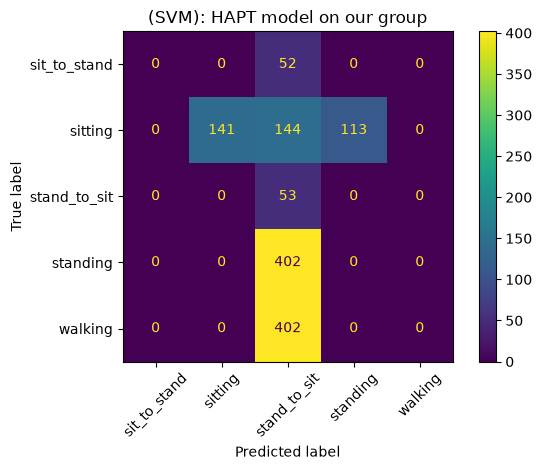

In [11]:
# A (SVM): HAPT model on our group
svm_hapt = make_pipeline(StandardScaler(), SVC())
svm_hapt.fit(hapt[BASE], hapt["activity"])
predictions = svm_hapt.predict(group[BASE])
report(group["activity"], predictions, "(SVM): HAPT model on our group")

(SVM): HAPT + group, new person
Accuracy: 0.8018362662586075
              precision    recall  f1-score   support

sit_to_stand       1.00      0.06      0.11        52
     sitting       1.00      0.59      0.74       398
stand_to_sit       1.00      0.11      0.20        53
    standing       0.80      1.00      0.89       402
     walking       0.72      1.00      0.83       402

    accuracy                           0.80      1307
   macro avg       0.90      0.55      0.56      1307
weighted avg       0.85      0.80      0.77      1307



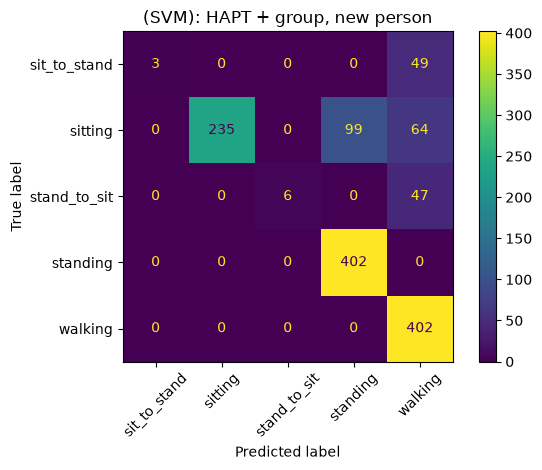

(SVM): group only, new person
Accuracy: 0.9709257842387146
              precision    recall  f1-score   support

sit_to_stand       1.00      0.67      0.80        52
     sitting       1.00      1.00      1.00       398
stand_to_sit       1.00      0.60      0.75        53
    standing       1.00      1.00      1.00       402
     walking       0.91      1.00      0.95       402

    accuracy                           0.97      1307
   macro avg       0.98      0.86      0.90      1307
weighted avg       0.97      0.97      0.97      1307



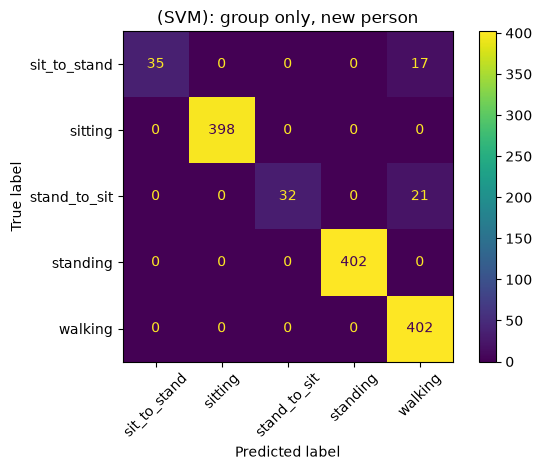

(SVM): group only + change features
Accuracy: 0.9510328997704667
              precision    recall  f1-score   support

sit_to_stand       1.00      0.56      0.72        52
     sitting       1.00      1.00      1.00       398
stand_to_sit       1.00      0.23      0.37        53
    standing       1.00      1.00      1.00       402
     walking       0.86      1.00      0.93       402

    accuracy                           0.95      1307
   macro avg       0.97      0.76      0.80      1307
weighted avg       0.96      0.95      0.94      1307



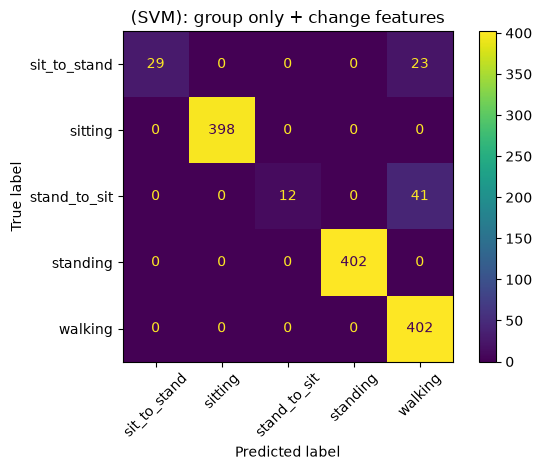

In [12]:
leave_one_person_out(BASE, "(SVM): HAPT + group, new person", extra_train=hapt, svm=True)
leave_one_person_out(BASE, "(SVM): group only, new person", svm=True)
leave_one_person_out(FEATURE_NAMES, "(SVM): group only + change features", svm=True)

user           P1   P2   P3   P4
activity                        
sit_to_stand   22   10   20   18
sitting       142  124  132  203
stand_to_sit   22   10   21   18
standing      142  128  132  124
walking       135  137  130  129
With P4 (phone orientation differs)
Accuracy: 0.8276820455808782
              precision    recall  f1-score   support

sit_to_stand       1.00      0.86      0.92        70
     sitting       0.68      1.00      0.81       601
stand_to_sit       1.00      0.85      0.92        71
    standing       1.00      0.52      0.69       526
     walking       0.96      0.93      0.94       531

    accuracy                           0.83      1799
   macro avg       0.93      0.83      0.85      1799
weighted avg       0.88      0.83      0.82      1799



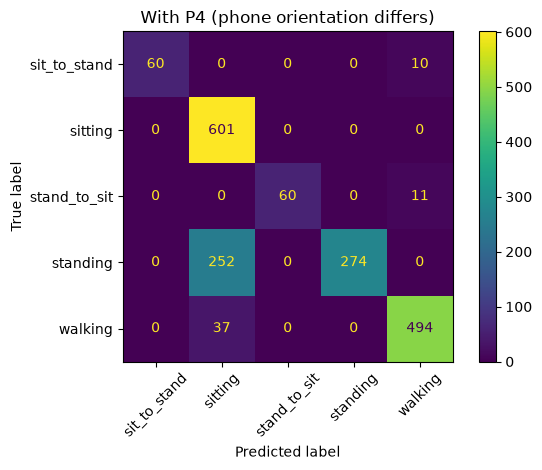

In [13]:
p4 = person_table("P4", f"{OWN}/P4")
group = pd.concat([p1, p2, p3, p4], ignore_index=True)
print(pd.crosstab(group["activity"], group["user"]))
leave_one_person_out(FEATURE_NAMES, "With P4 (phone orientation differs)")

With P4 (SVM): group only, new person
Accuracy: 0.8371317398554753
              precision    recall  f1-score   support

sit_to_stand       1.00      0.97      0.99        70
     sitting       0.70      1.00      0.82       601
stand_to_sit       0.71      0.85      0.77        71
    standing       1.00      0.53      0.69       526
     walking       0.97      0.95      0.96       531

    accuracy                           0.84      1799
   macro avg       0.88      0.86      0.85      1799
weighted avg       0.88      0.84      0.83      1799



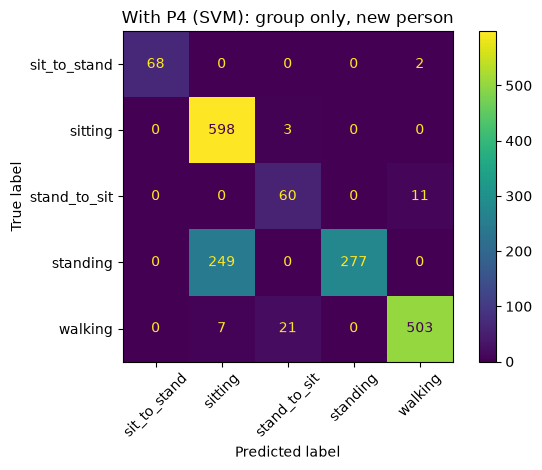

With P4 (SVM): group only + change features
Accuracy: 0.8499166203446359
              precision    recall  f1-score   support

sit_to_stand       1.00      0.99      0.99        70
     sitting       0.70      1.00      0.82       601
stand_to_sit       0.98      0.87      0.93        71
    standing       1.00      0.52      0.69       526
     walking       0.98      0.98      0.98       531

    accuracy                           0.85      1799
   macro avg       0.93      0.87      0.88      1799
weighted avg       0.89      0.85      0.84      1799



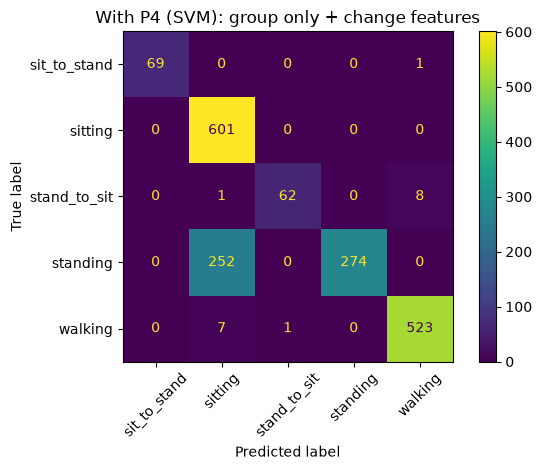

In [14]:
leave_one_person_out(BASE, "With P4 (SVM): group only, new person", svm=True)
leave_one_person_out(FEATURE_NAMES, "With P4 (SVM): group only + change features", svm=True)

In [15]:
for name in results:
    score = results[name]
    print(f"{name}: macro F1 = {score:.3f}")

HAPT model on our group: macro F1 = 0.523
HAPT + group, new person: macro F1 = 0.721
group only, new person: macro F1 = 0.868
group only + change features: macro F1 = 0.944
(SVM): HAPT model on our group: macro F1 = 0.124
(SVM): HAPT + group, new person: macro F1 = 0.556
(SVM): group only, new person: macro F1 = 0.902
(SVM): group only + change features: macro F1 = 0.802
With P4 (phone orientation differs): macro F1 = 0.855
With P4 (SVM): group only, new person: macro F1 = 0.846
With P4 (SVM): group only + change features: macro F1 = 0.882
